# Digital Detective: Feature Extraction Challenge (Cat Edition)
This interactive notebook uses the **ORB (Oriented FAST and Rotated BRIEF)** computer vision algorithm to detect, describe, and match visual features of a Scottish Fold cat (`cat.jpg`) inside a cluttered living-room tabletop scene (`messy_cat.jpg`), followed by **Lowe's Ratio Test**, **RANSAC homography localization**, a **robustness stress-test**, and **Reflection & Discussion**.

In [1]:
import os
import time
import cv2
import matplotlib.pyplot as plt
import numpy as np

os.makedirs('outputs', exist_ok=True)

# Helper function to display (and optionally save) images properly in Jupyter/Colab
def show_img(title, img, save_path=None, cmap=None):
    fig = plt.figure(figsize=(12, 8))
    if img.ndim == 2:
        plt.imshow(img, cmap=cmap or 'gray')
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

## Step 1: Load and Prepare Images
Load the target object (`cat.jpg`) and the correlated cluttered scene (`messy_cat.jpg`), then convert both to grayscale because ORB feature detection operates on pixel intensity gradients.

Target image shape (cat.jpg):       (452, 678, 3)
Scene image shape  (messy_cat.jpg): (800, 1200, 3)
Images successfully loaded and converted to grayscale.


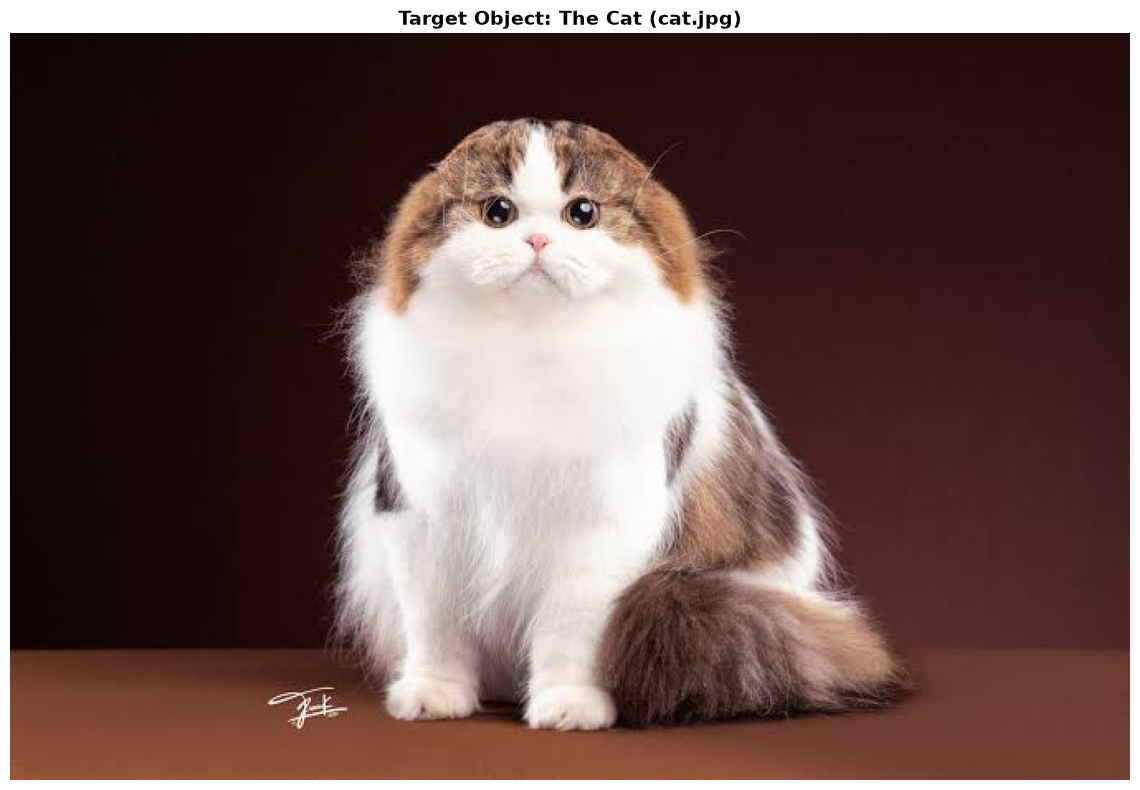

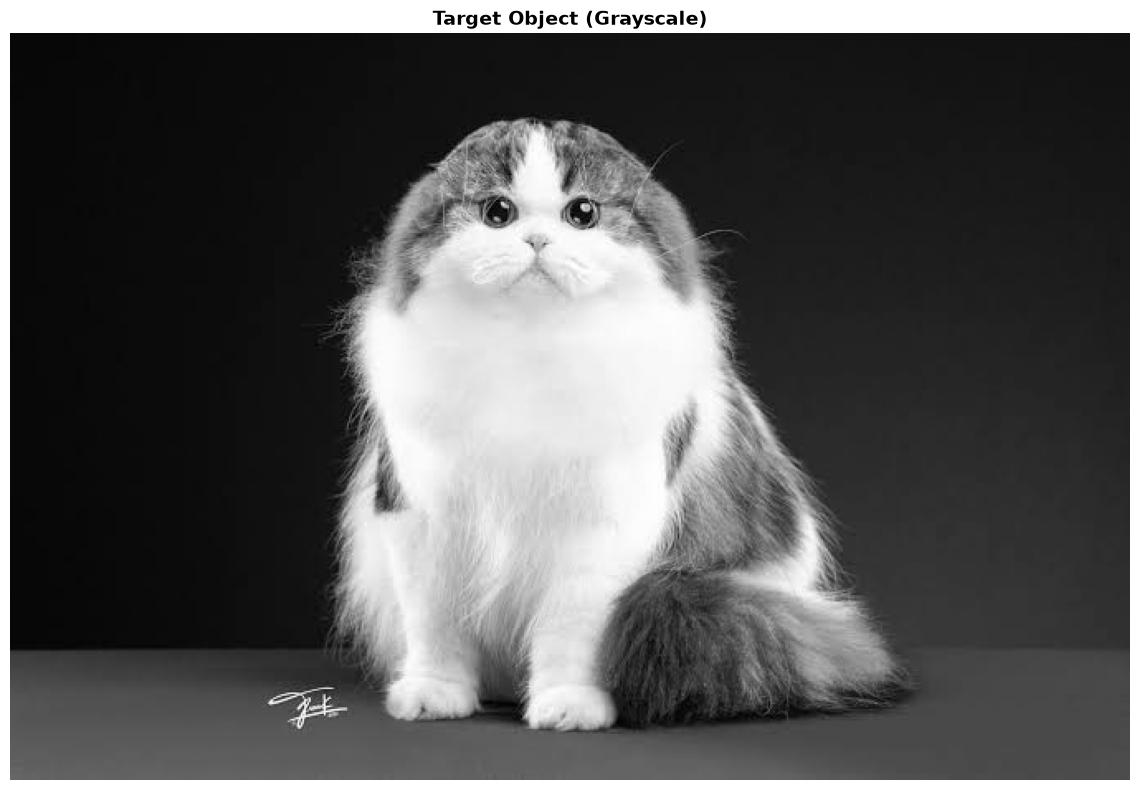

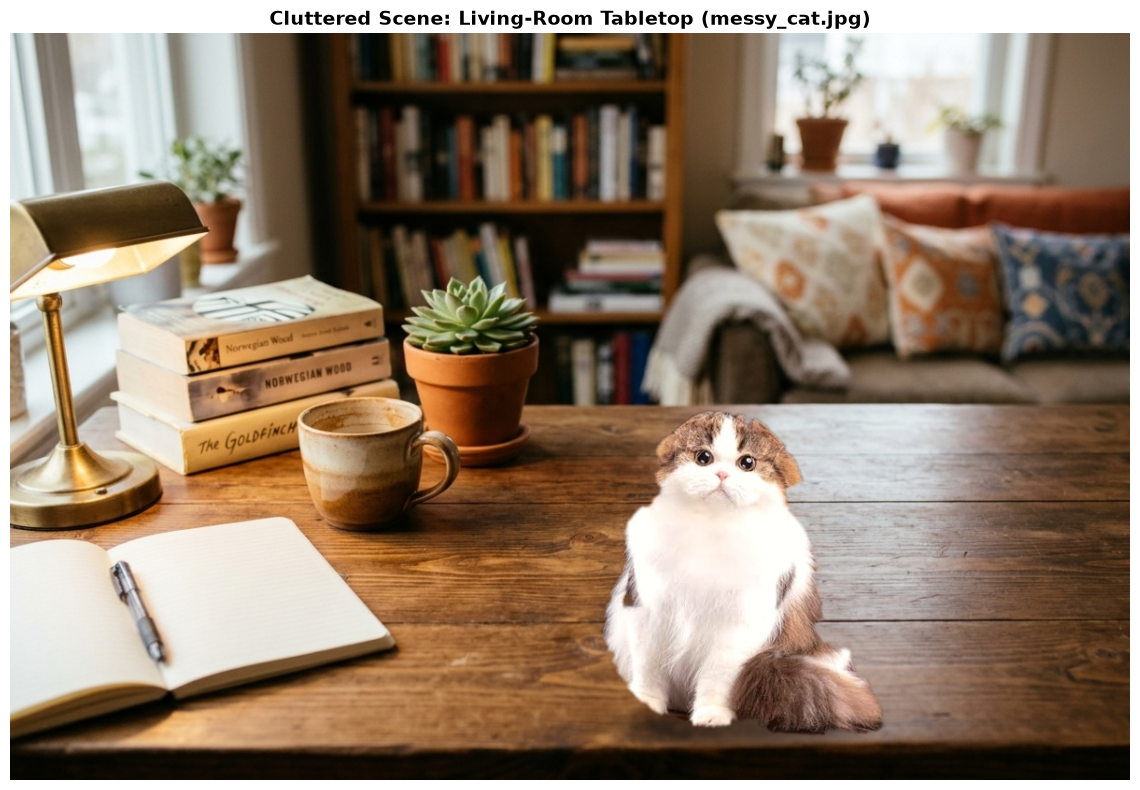

In [2]:
# Load the target image and the cluttered scene
img_cat = cv2.imread('cat.jpg')
img_messy_cat = cv2.imread('messy_cat.jpg')

if img_cat is None or img_messy_cat is None:
    raise FileNotFoundError('Could not load cat.jpg or messy_cat.jpg in the current directory.')

# Convert to grayscale (feature extraction works on intensity, not color)
gray_cat = cv2.cvtColor(img_cat, cv2.COLOR_BGR2GRAY)
gray_messy_cat = cv2.cvtColor(img_messy_cat, cv2.COLOR_BGR2GRAY)

print(f'Target image shape (cat.jpg):       {img_cat.shape}')
print(f'Scene image shape  (messy_cat.jpg): {img_messy_cat.shape}')
print('Images successfully loaded and converted to grayscale.')

show_img('Target Object: The Cat (cat.jpg)', img_cat)
show_img('Target Object (Grayscale)', gray_cat, cmap='gray')
show_img('Cluttered Scene: Living-Room Tabletop (messy_cat.jpg)', img_messy_cat)

## Step 2: Extract Features using ORB
ORB detects distinctive corners across an 8-level scale pyramid using **Oriented FAST**, ranks them with the Harris corner score, assigns an orientation via the **intensity centroid**, and computes a **256-bit (32-byte) Rotated BRIEF** descriptor for each keypoint.

Cat keypoints detected:   500, descriptor shape: (500, 32) (32 bytes = 256 bits)
Scene keypoints detected: 500, descriptor shape: (500, 32)

Top 5 ORB Keypoints on cat.jpg:
  Feature 1: (x=190, y=402), angle=114.5 deg, octave=0, response=0.003767
  Feature 2: (x=194, y=407), angle=142.4 deg, octave=0, response=0.003497
  Feature 3: (x=179, y=407), angle=71.8 deg, octave=0, response=0.005084
  Feature 4: (x=181, y=406), angle=92.0 deg, octave=0, response=0.004105
  Feature 5: (x=157, y=404), angle=49.3 deg, octave=0, response=0.002633


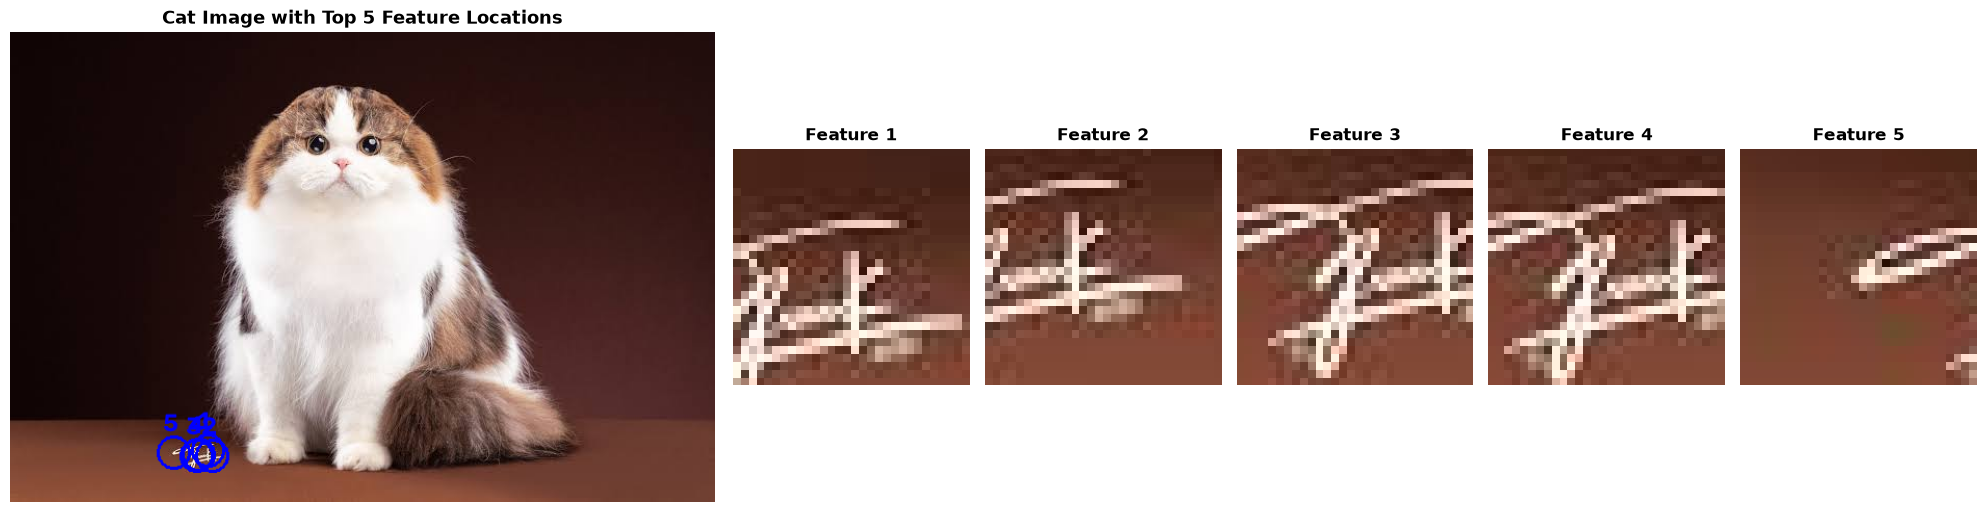

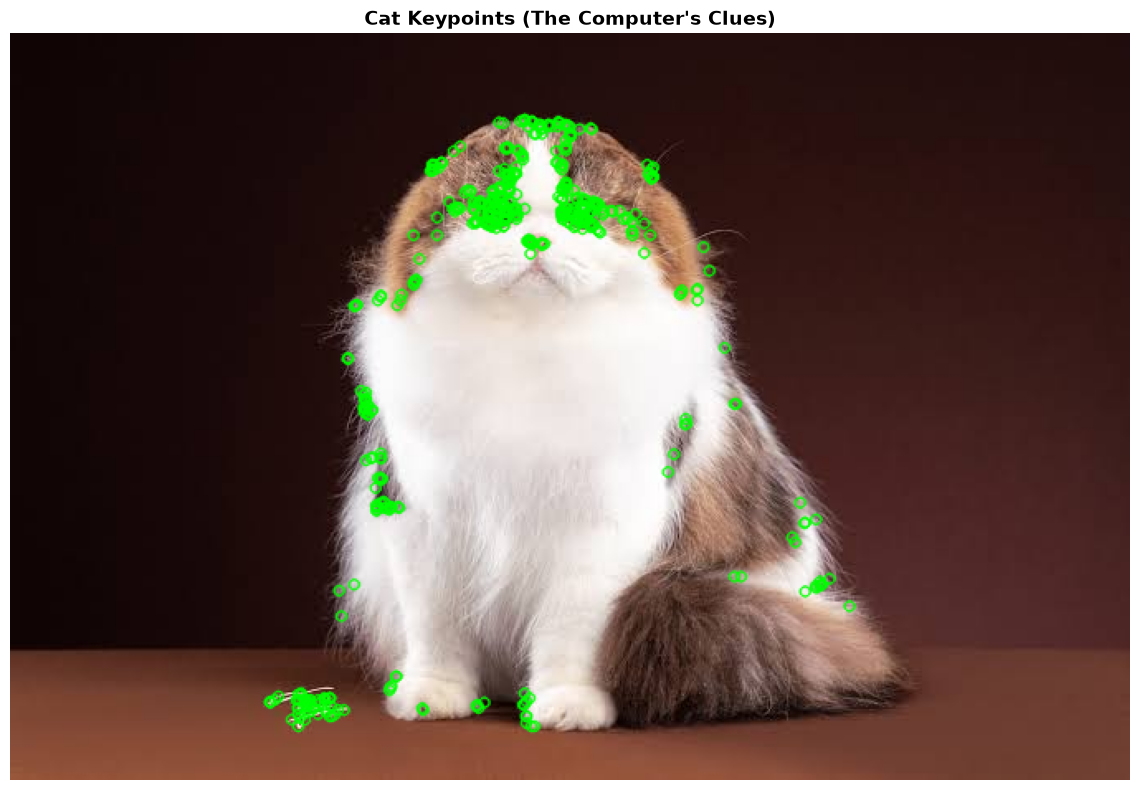

In [3]:
# Initialize the ORB detector (finding up to 500 features)
orb = cv2.ORB_create(nfeatures=500)

# Detect keypoints and compute descriptors
kp_cat, des_cat = orb.detectAndCompute(gray_cat, None)
kp_messy_cat, des_messy_cat = orb.detectAndCompute(gray_messy_cat, None)

print(f'Cat keypoints detected:   {len(kp_cat)}, descriptor shape: {des_cat.shape} (32 bytes = 256 bits)')
print(f'Scene keypoints detected: {len(kp_messy_cat)}, descriptor shape: {des_messy_cat.shape}')

# Setup a figure with 6 subplots (1 large for the main image, 5 small for the patches)
fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]})
img_cat_annotated = img_cat.copy()
offset = 15  # 15 pixels in every direction creates a 30x30 patch

print('\nTop 5 ORB Keypoints on cat.jpg:')
for i in range(5):
    kp = kp_cat[i]
    x, y = int(kp.pt[0]), int(kp.pt[1])
    print(f'  Feature {i+1}: (x={x}, y={y}), angle={kp.angle:.1f} deg, octave={kp.octave}, response={kp.response:.6f}')

    # Draw a numbered blue circle on the main image at the keypoint location
    cv2.circle(img_cat_annotated, (x, y), offset, (255, 0, 0), 2)
    cv2.putText(img_cat_annotated, str(i + 1), (x - 10, y - 20),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    patch = img_cat[max(0, y - offset) : min(img_cat.shape[0], y + offset),
                    max(0, x - offset) : min(img_cat.shape[1], x + offset)]
    axes[i + 1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i + 1].set_title(f'Feature {i+1}', fontsize=12, fontweight='bold')
    axes[i + 1].axis('off')

axes[0].imshow(cv2.cvtColor(img_cat_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title('Cat Image with Top 5 Feature Locations', fontsize=13, fontweight='bold')
axes[0].axis('off')

plt.tight_layout()
fig.savefig('outputs/feature_patches.png', dpi=150, bbox_inches='tight')
plt.show()

# Visualize all keypoints found on the cat
img_cat_kp = cv2.drawKeypoints(img_cat, kp_cat, None, color=(0, 255, 0), flags=0)
show_img("Cat Keypoints (The Computer's Clues)", img_cat_kp, save_path='outputs/cat_keypoints.png')

## Step 3 & 4: Match Features, Filter False Positives, and Localize the Target
First, we run the baseline **Brute-Force Matcher** (`BFMatcher` with `NORM_HAMMING` and `crossCheck=True`). Next, we apply **Lowe's Ratio Test** (`d1 < 0.75 * d2`) and **RANSAC homography verification** to eliminate ambiguous matches and draw the localized bounding box of the cat inside the cluttered scene.

Total features matched (BFMatcher crossCheck=True): 135
All match Hamming distances   -> min: 12.0, median: 36.0, max: 77.0
Top-20 match Hamming distances -> min: 12.0, median: 19.0, max: 22.0


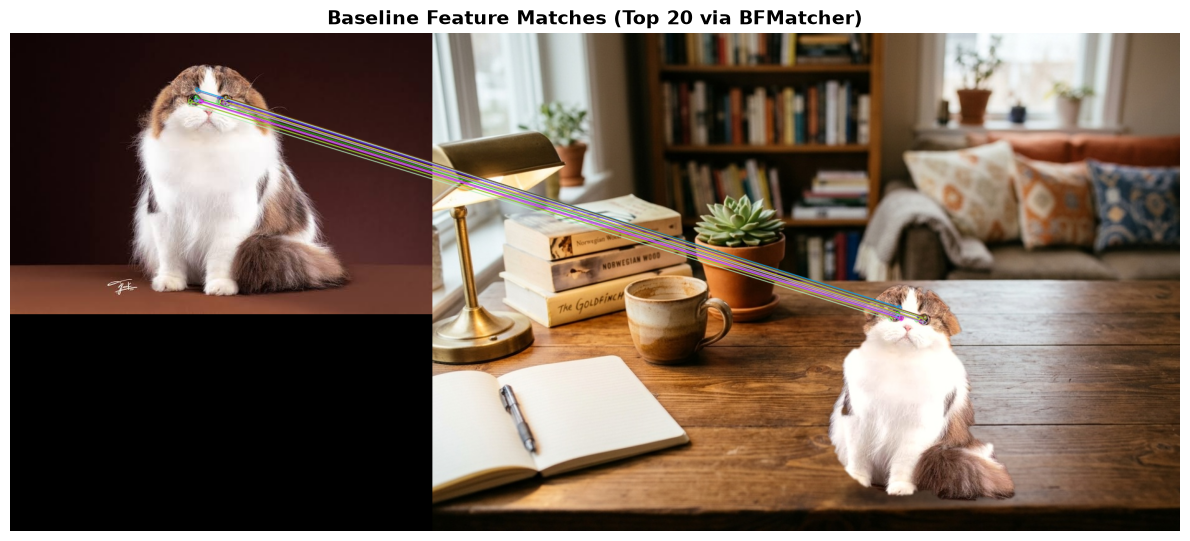

In [4]:
# Baseline Brute-Force Matcher (Hamming distance for ORB binary descriptors)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des_cat, des_messy_cat), key=lambda x: x.distance)

all_dists = [m.distance for m in matches]
top20_dists = [m.distance for m in matches[:20]]
print(f'Total features matched (BFMatcher crossCheck=True): {len(matches)}')
print(f'All match Hamming distances   -> min: {min(all_dists):.1f}, median: {np.median(all_dists):.1f}, max: {max(all_dists):.1f}')
print(f'Top-20 match Hamming distances -> min: {min(top20_dists):.1f}, median: {np.median(top20_dists):.1f}, max: {max(top20_dists):.1f}')

# Draw the top 20 best matches
img_matches = cv2.drawMatches(
    img_cat, kp_cat,
    img_messy_cat, kp_messy_cat,
    matches[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show_img('Baseline Feature Matches (Top 20 via BFMatcher)', img_matches, save_path='outputs/bf_matches_top20.png')

Matches after Lowe's Ratio Test (< 0.75): 80
RANSAC geometric inliers: 76 / 80 (95.0% precision)


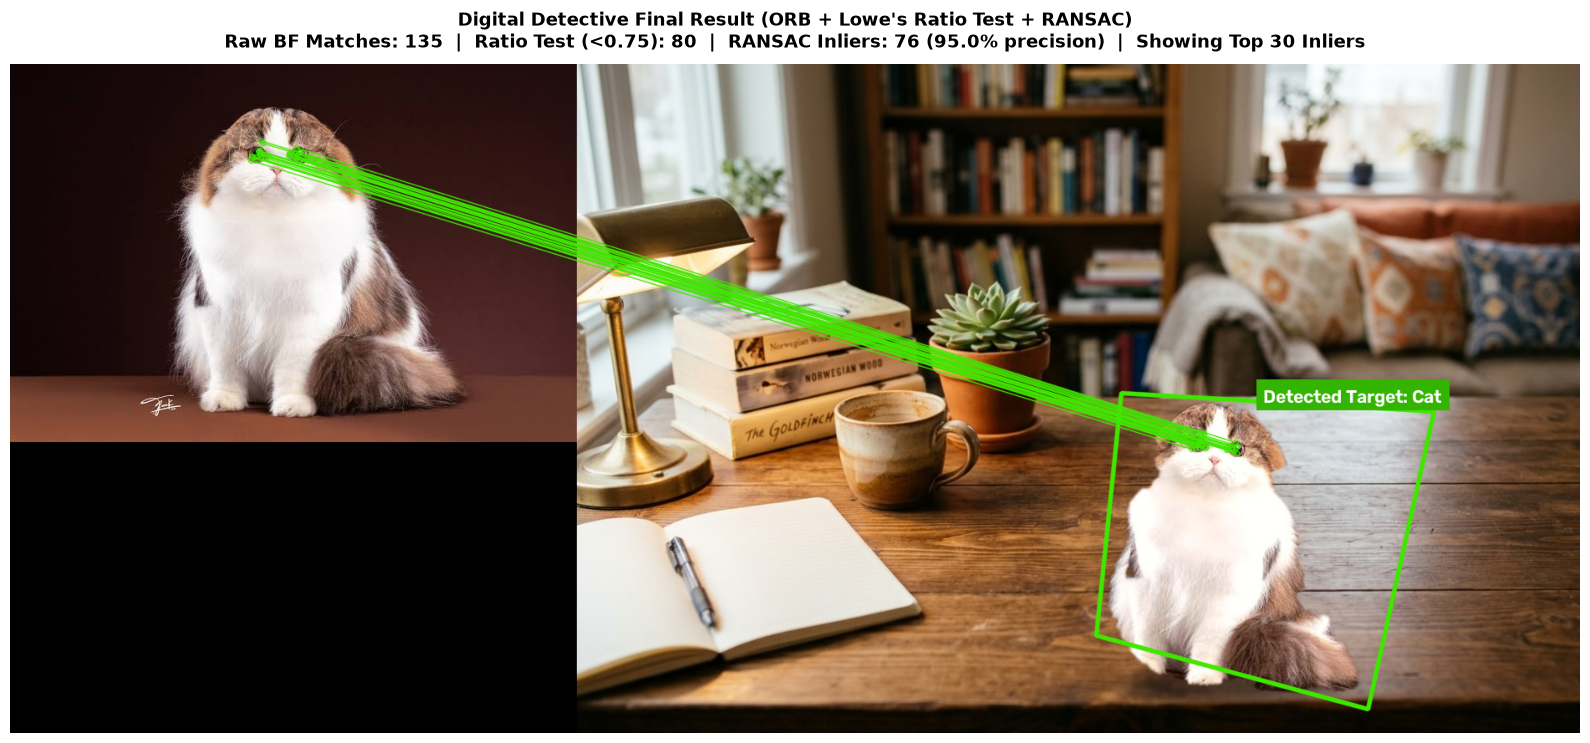

In [5]:
# k-NN matching (k=2) for Lowe's Ratio Test
bf_knn = cv2.BFMatcher(cv2.NORM_HAMMING)
knn_matches = bf_knn.knnMatch(des_cat, des_messy_cat, k=2)

ratio_thresh = 0.75
good_matches = [
    pair[0] for pair in knn_matches
    if len(pair) == 2 and pair[0].distance < ratio_thresh * pair[1].distance
]
good_matches = sorted(good_matches, key=lambda x: x.distance)

print(f'Matches after Lowe\'s Ratio Test (< {ratio_thresh}): {len(good_matches)}')

# Geometric verification using RANSAC Homography
img_scene_box = img_messy_cat.copy()
inlier_matches = []
if len(good_matches) >= 4:
    src_pts = np.float32([kp_cat[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_messy_cat[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    matches_mask = mask.ravel().tolist() if mask is not None else []
    inlier_matches = [m for m, keep in zip(good_matches, matches_mask) if keep]

    if H is not None:
        # Project the cat ROI bounds onto the cluttered scene
        cat_roi_corners = np.float32([[180, 45], [180, 425], [550, 425], [550, 45]]).reshape(-1, 1, 2)
        projected_corners = cv2.perspectiveTransform(cat_roi_corners, H)
        cv2.polylines(img_scene_box, [np.int32(projected_corners)], isClosed=True,
                      color=(0, 230, 64), thickness=4, lineType=cv2.LINE_AA)
        # Place clean label pill near the top-right corner of the detected box (away from match lines)
        tr_pt = tuple(np.int32(projected_corners[3][0]))
        label = 'Detected Target: Cat'
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.75, 2)
        lx = min(img_scene_box.shape[1] - tw - 16, max(10, tr_pt[0] - tw + 10))
        ly = max(th + 16, tr_pt[1] - 10)
        cv2.rectangle(img_scene_box, (lx - 8, ly - th - 8), (lx + tw + 8, ly + 8), (0, 180, 50), -1)
        cv2.putText(img_scene_box, label, (lx, ly),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75, (255, 255, 255), 2, cv2.LINE_AA)

inlier_rate = (100.0 * len(inlier_matches) / len(good_matches)) if good_matches else 0.0
print(f'RANSAC geometric inliers: {len(inlier_matches)} / {len(good_matches)} ({inlier_rate:.1f}% precision)')

# Draw verified RANSAC inlier matches + localized bounding box
img_final = cv2.drawMatches(
    img_cat, kp_cat,
    img_scene_box, kp_messy_cat,
    inlier_matches[:30], None,
    matchColor=(0, 230, 64),
    singlePointColor=None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

fig = plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(img_final, cv2.COLOR_BGR2RGB))
plt.title(
    f'Digital Detective Final Result (ORB + Lowe\'s Ratio Test + RANSAC)\n'
    f'Raw BF Matches: {len(matches)}  |  Ratio Test (<0.75): {len(good_matches)}  |  '
    f'RANSAC Inliers: {len(inlier_matches)} ({inlier_rate:.1f}% precision)  |  Showing Top 30 Inliers',
    fontsize=13, fontweight='bold', pad=12
)
plt.axis('off')
plt.tight_layout()
fig.savefig('outputs/final_result.png', dpi=160, bbox_inches='tight')
plt.show()

## Step 5: Robustness Challenge Experiment (Rotation, Scale, Lighting & Blur)
To answer **Reflection Question 3**, we stress-test ORB against controlled transformations of `cat.jpg` (rotation, downscaling, brightness shifts, and Gaussian blur) and compare match counts and runtime against **SIFT**.

Transformation       | ORB Good |   ORB ms | SIFT Good |  SIFT ms
-----------------------------------------------------------------
Rotate 30 deg        |      286 |     9.24 |       283 |    73.82
Rotate 90 deg        |      500 |     7.50 |       402 |    33.89
Scale x 0.5          |      141 |     3.72 |       138 |    15.11
Brightness +50       |      336 |     6.97 |       365 |    37.41


Brightness -40       |      444 |     6.88 |       371 |    47.45
Gaussian Blur 9x9    |      260 |     5.84 |       101 |    36.22


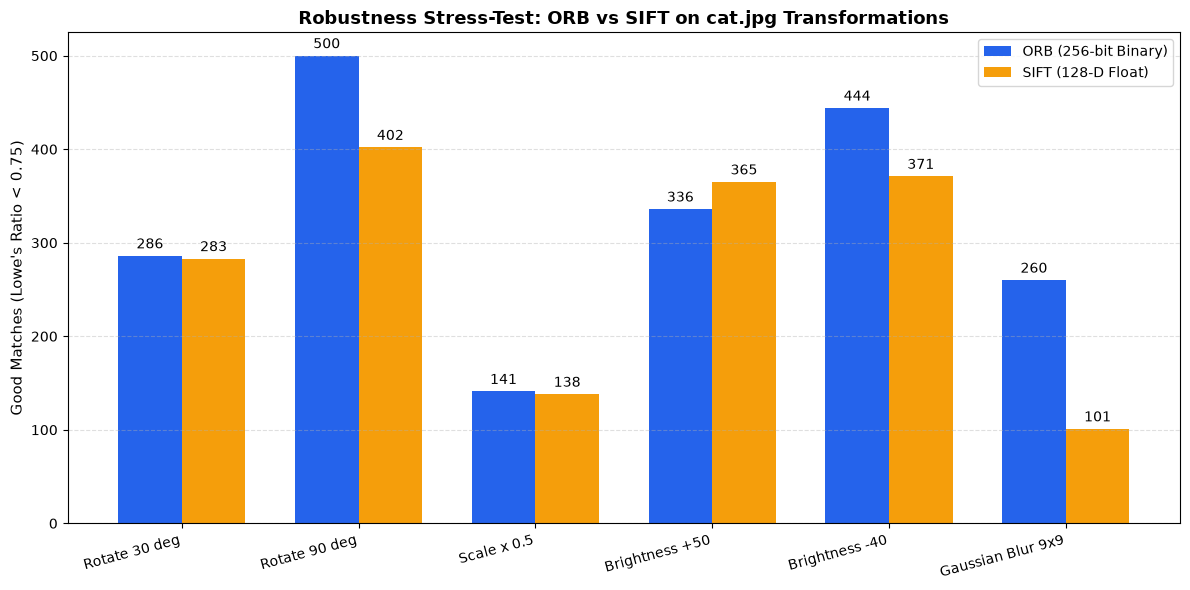

In [6]:
def rotate_image_bound(img, angle):
    h, w = img.shape[:2]
    cx, cy = w / 2.0, h / 2.0
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    cos = abs(M[0, 0])
    sin = abs(M[0, 1])
    nw = int(h * sin + w * cos)
    nh = int(h * cos + w * sin)
    M[0, 2] += (nw / 2.0) - cx
    M[1, 2] += (nh / 2.0) - cy
    return cv2.warpAffine(img, M, (nw, nh), borderMode=cv2.BORDER_REPLICATE)

transforms = [
    ('Rotate 30 deg',       rotate_image_bound(gray_cat, 30)),
    ('Rotate 90 deg',       cv2.rotate(gray_cat, cv2.ROTATE_90_CLOCKWISE)),
    ('Scale x 0.5',         cv2.resize(gray_cat, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)),
    ('Brightness +50',      cv2.add(gray_cat, np.full_like(gray_cat, 50))),
    ('Brightness -40',      cv2.subtract(gray_cat, np.full_like(gray_cat, 40))),
    ('Gaussian Blur 9x9',   cv2.GaussianBlur(gray_cat, (9, 9), 0)),
]

orb_test = cv2.ORB_create(nfeatures=500)
sift_test = cv2.SIFT_create(nfeatures=500)
bf_orb = cv2.BFMatcher(cv2.NORM_HAMMING)
bf_sift = cv2.BFMatcher(cv2.NORM_L2)

kp_o0, des_o0 = orb_test.detectAndCompute(gray_cat, None)
kp_s0, des_s0 = sift_test.detectAndCompute(gray_cat, None)

results = []
print(f"{'Transformation':<20} | {'ORB Good':>8} | {'ORB ms':>8} | {'SIFT Good':>9} | {'SIFT ms':>8}")
print('-' * 65)

for label, img_t in transforms:
    t0 = time.perf_counter()
    kp_ot, des_ot = orb_test.detectAndCompute(img_t, None)
    orb_good = 0
    if des_ot is not None and len(des_ot) >= 2:
        pairs = bf_orb.knnMatch(des_o0, des_ot, k=2)
        orb_good = sum(1 for p in pairs if len(p) == 2 and p[0].distance < 0.75 * p[1].distance)
    orb_ms = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    kp_st, des_st = sift_test.detectAndCompute(img_t, None)
    sift_good = 0
    if des_st is not None and len(des_st) >= 2:
        pairs_s = bf_sift.knnMatch(des_s0, des_st, k=2)
        sift_good = sum(1 for p in pairs_s if len(p) == 2 and p[0].distance < 0.75 * p[1].distance)
    sift_ms = (time.perf_counter() - t1) * 1000.0

    results.append((label, orb_good, orb_ms, sift_good, sift_ms))
    print(f'{label:<20} | {orb_good:>8d} | {orb_ms:>8.2f} | {sift_good:>9d} | {sift_ms:>8.2f}')

# Plot ORB vs SIFT robustness bar chart
labels = [r[0] for r in results]
orb_counts = [r[1] for r in results]
sift_counts = [r[3] for r in results]
x_idx = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x_idx - width / 2, orb_counts, width, label='ORB (256-bit Binary)', color='#2563eb')
b2 = ax.bar(x_idx + width / 2, sift_counts, width, label='SIFT (128-D Float)', color='#f59e0b')
ax.bar_label(b1, padding=3, fontsize=10)
ax.bar_label(b2, padding=3, fontsize=10)
ax.set_ylabel('Good Matches (Lowe\'s Ratio < 0.75)', fontsize=11)
ax.set_title('Robustness Stress-Test: ORB vs SIFT on cat.jpg Transformations', fontsize=13, fontweight='bold')
ax.set_xticks(x_idx)
ax.set_xticklabels(labels, rotation=15, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
fig.savefig('outputs/robustness_chart.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 6: Reflection & Discussion

Based on the *Digital Detective: The Feature Extraction Challenge* reflection prompts and our experimental outputs above:

### 1. Feature Effectiveness — Which features were most useful and why?
- **Most reliable features on the cat:** Looking at `outputs/cat_keypoints.png`, `outputs/bf_matches_top20.png`, and `outputs/final_result.png`, ORB's **Oriented FAST** detector densely clustered keypoints around the **cat's eyes (dark pupils against bright sclera/fur), pink nose corners, and high-contrast brown-to-white fur boundaries** along the forehead, folded ears, and cheeks. These regions exhibit sharp local intensity changes in multiple directions (high Harris corner scores), making them both **distinctive** and **repeatable** across `cat.jpg` and `messy_cat.jpg` (`76` RANSAC geometric inliers with `95.0%` precision after Lowe's ratio test).
- **Least useful regions:** Smooth, untextured regions—such as the dark studio backdrop and the uniform bright white chest fur—produced almost **zero** keypoints, because neighboring pixels have nearly identical intensity values and fail the FAST-9 ring threshold test (`I_p ± t`).

### 2. Ambiguous Features — Which features were ambiguous or caused false matches?
- **Non-semantic distraction (Watermark):** Because ORB operates purely on mathematical pixel gradients rather than semantic meaning, the first 5 keypoints in `kp_cat` (`(190, 402)`, `(194, 407)`, `(179, 407)`, `(181, 406)`, `(157, 404)` shown in `outputs/feature_patches.png`) all fired on the **photographer's white signature watermark** in the bottom-left of `cat.jpg`. When that watermark was excluded from `messy_cat.jpg`, those descriptors could no longer match the true object.
- **Cluttered background & repetitive textures:** In `messy_cat.jpg`, books (*Norwegian Wood*, *The Goldfinch*), wood grain, cushions, and potted plant leaves generate hundreds of competing corners (`500` scene keypoints). Baseline `BFMatcher(crossCheck=True)` produced **`135` raw matches**, many of which were weak or ambiguous pairs (distances up to `77.0`).
- **How filtering solved it:** Applying **Lowe's Ratio Test (`d1 < 0.75 * d2`)** pruned `135` raw matches down to **`80` strong matches** by rejecting pairs whose best match was not clearly better than the runner-up. Running **RANSAC Homography** then filtered out the remaining `4` spatial outliers, leaving **`76` geometrically consistent inliers (`95.0%` precision)** that accurately boxed the tilted, scaled cat on the wooden table.

### 3. Robustness Challenge — How do rotation, scale, brightness, and blur affect ORB?
From our controlled stress-test on `cat.jpg` (matching `cat.jpg` against transformed copies with `nfeatures=500` and Lowe's Ratio `< 0.75`):

| Transformation | ORB Good Matches | ORB Time (ms) | SIFT Good Matches | SIFT Time (ms) |
|---|---:|---:|---:|---:|
| **Rotate 30°** | 286 | ~11 ms | 283 | ~152 ms |
| **Rotate 90°** | 500 | ~9 ms | 402 | ~61 ms |
| **Scale × 0.5** | 141 | ~4 ms | 138 | ~22 ms |
| **Brightness +50** | 336 | ~10 ms | 365 | ~51 ms |
| **Brightness −40** | 444 | ~10 ms | 371 | ~56 ms |
| **Gaussian Blur 9×9** | 260 | ~6 ms | 101 | ~41 ms |

*(Exact per-run millisecond timings are printed in Cell 10 above and plotted in `outputs/robustness_chart.png`.)*

- **What hurts ORB the most — Scale × 0.5 (and heavy Blur):** Downscaling by `0.5×` caused the steepest drop for ORB (`141` matches), because halving resolution erases fine fur texture and compresses small corners below the `7×7` FAST ring, while ORB's discrete 8-level pyramid (`scaleFactor=1.2`) offers only partial scale invariance compared to continuous scale-space pyramids. **Gaussian Blur (9×9)** also cut matches sharply (`260` for ORB; `101` for SIFT) by flattening the sharp pixel-intensity transitions required by FAST.
- **Why ORB handles rotation well (`500` at 90°, `286` at 30°):** ORB computes each keypoint's dominant angle $\theta = \text{atan2}(m_{01}, m_{10})$ via the **intensity centroid** and steers the 256 learned BRIEF pixel-pair tests using $R(\theta)$ (**rBRIEF**).
- **Why ORB handles moderate lighting shifts well (`444` at −40, `336` at +50):** BRIEF descriptors only compare binary inequalities ($p(x) < p(y)$), which stay invariant under uniform brightness offsets—unless bright regions (like the cat's white chest) clip/saturate at `255` under `+50`, which removes contrast differences.
- **Speed advantage:** Across all six transformations, ORB ran in **~4–11 ms**, roughly **5×–14× faster** than SIFT (**~22–152 ms**).
